# 3.0 Transformacion JobPath (CRISP-DM fase 3, preparacion de datos)

**Fase CRISP-DM:** 3. Data Preparation, bloque de transformacion/reduccion.
**Enlace con el negocio (charter):** "descubrir y caracterizar patrones de transicion ocupacional en trayectorias post-formacion, mediante tecnicas de mineria sobre secuencias (no supervisada)".
**Recibe:** `empleos_limpio_con_competencias.csv` (con outliers) y `empleos_limpio_con_competencias_sin_outliers.csv` (IQR winsorizada).
**Entrega:** `X_train`, `X_test` (y `y_train`, `y_test` para `reincide`), transformers guardados con joblib, PCA diagnostico y bitacora.

**Prerequisito:** ejecutar primero `2.0_preprocesamiento_jobpath.ipynb` para que B este winsorizada y con trazabilidad.


In [1]:
# Celda 1: librerias, rutas relativas y semillas fijas
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Preproccesing.config import DEFAULT_CONFIG
from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.comparison import material_difference_summary, pair_distance_analysis
from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
from scripts.ScriptsCsv.Transformacion.decision_log import DecisionLog
from scripts.ScriptsCsv.Transformacion.discretization import fit_discretizers, report_edges, transform_discretizers
from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence, fit_onehot, ordinal_from_mapping, reduce_high_cardinality, transform_onehot
from scripts.ScriptsCsv.Transformacion.export import ensure_dir, save_frame, save_transformers
from scripts.ScriptsCsv.Transformacion.scaler_recommendation import recommend_scalers
from scripts.ScriptsCsv.Transformacion.scaling import fit_transform_full, scaled_column_name
from scripts.ScriptsCsv.Transformacion.split import fit_transform_train_test, group_train_test_split
from scripts.ScriptsCsv.Transformacion.validation import assert_validation, validate_transformed

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

VERSION_CON = "con_outliers"
VERSION_SIN = "sin_outliers"
TRANSFORMED_ROOT = ROOT / "data" / "04_transformed"

print("Raiz:", ROOT)
print("Transformed root:", TRANSFORMED_ROOT)


Raiz: C:\Users\User\Documents\JobPath\MineriaProtect
Transformed root: C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed


In [2]:
# Celda 2: configuracion de negocio y transformacion
TARGET_MODE = "reincide"          # Y auxiliar: no supervisada pura; solo se usa para interpretar/estabilidad
TEST_SIZE = 0.20
RANDOM_SEED = 42
HIGH_CARD_STRATEGY = "all"        # all | top_n | frequency_threshold | prefix

# Columnas num?ricas seleccionadas (no se escalan identificadores, codigos ni dummies)
SELECTED_NUMERIC = [
    "start_ord", "end_ord", "dur_q",
    "n_skills_essential", "n_skills_competence",
    "n_skills_knowledge", "n_skills_sin_tipo",
    "veces_ese_oficio", "start_year", "job_order",
]

# Plan de escalado (evidencia en recommend_scalers)
SCALING_PLAN = {
    "start_ord": "robust",            # cola real por fechas antiguas
    "end_ord": "robust",
    "dur_q": "robust",
    "n_skills_essential": "robust",    # escala y outliers reales
    "n_skills_competence": "robust",
    "n_skills_knowledge": "robust",
    "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust",
    "start_year": "robust",
    "job_order": "robust",
    "univ_ord": "minmax",               # rango acotado sin outliers graves
}

# Columnas nominales para one-hot (occupation_code alta cardinalidad: se conserva por decision aprobada)
ONEHOT_COLUMNS = ["emparejado", "occupation_code"]
ONEHOT_DROP_FIRST = True            # evita multicolinealidad y una categoria de referencia

# Ordinal manual solo para jerarquia genuina
UNIV_ORDER = {
    "No reportado": 0,
    "Secondary school": 1,
    "Bachelor": 2,
    "Master": 3,
    "PhD": 4,
}

# Discretizacion con lectura de negocio
DISCRETIZATION_COLUMNS = ["dur_q", "n_skills_essential", "veces_ese_oficio"]
DISCRETIZATION_SPEC = {
    "columns": DISCRETIZATION_COLUMNS,
    "n_bins": 4,
    "strategy": "quantile",
    "labels": {
        "dur_q": ["trayectoria corta", "trayectoria media", "trayectoria larga", "trayectoria muy larga"],
        "n_skills_essential": ["oficio de baja carga", "oficio de carga media", "oficio de alta carga", "oficio de carga muy alta"],
        "veces_ese_oficio": ["single", "reincidencia baja", "reincidencia media", "reincidencia alta"],
    },
}

# Binarias sin escalar
BINARY_COLUMNS = ["es_vigente"]
PRESENCE_COLUMNS = ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"]
EXPORT_DECISION_LOG = False


## 1. Select data: perfil completo de ambas versiones

Se leen **una sola vez** y en RAM con `dtype=str`, sin modificar los CSV. Despues se derivan fechas, orden del empleo y presencia de competencias. El perfil incluye dtype, nulos, cardinalidad, porcentaje de ceros, skew, kurtosis y clasificacion de tipo.


In [3]:
def read_version(version):
    from scripts.ScriptsCsv.Transformacion.config import processed_path
    from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
    from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    # Recuperar codigo de las filas marcadas como rescatadas (misma logica que src/transformacion)
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")

    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    skill_cols = ["skills", "knowledge", "sin_tipo"]
    flag_cols = ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"]
    df = derive_skill_presence(df, skill_cols, flag_cols)
    if "university_level" in df.columns:
        df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    else:
        df["univ_ord"] = 0
    for col in ["es_unknown_ocupacion", "es_rescatado", "es_vigente"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.lower().map({"true": 1, "false": 0}).fillna(0).astype("int8")
    df["reincide"] = (df["veces_ese_oficio"].fillna(0) > 1).astype("int8")
    if HIGH_CARD_STRATEGY != "all":
        df["occupation_code"] = reduce_high_cardinality(df["occupation_code"], HIGH_CARD_STRATEGY)
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
print("Versiones cargadas:", df_con.shape, df_sin.shape)


Versiones cargadas: (376567, 33) (376567, 33)


In [4]:
profiles = pd.concat(
    [profile_columns(df_con, VERSION_CON), profile_columns(df_sin, VERSION_SIN)],
    ignore_index=True,
)
display(profiles[["version", "column", "dtype", "n_null", "cardinality", "zero_pct", "skewness", "kurtosis", "type_class", "relevant", "reason"]])
print("\nColumnas relevantes version con outliers:", int(profiles.loc[(profiles.version == VERSION_CON) & profiles.relevant, "column"].nunique()))


,version,column,dtype,n_null,cardinality,zero_pct,skewness,kurtosis,type_class,relevant,reason
0,con_outliers,resume_id,str,0,71061,0.000000,-0.001356,-1.193055,identifier,False,Identificador de persona: indispensable para e...
1,con_outliers,start_date,str,0,206,NaN,NaN,NaN,date,True,Fecha de inicio del empleo: se deriva a ordina...
2,con_outliers,end_date,str,0,210,NaN,NaN,NaN,date,True,Fecha de fin o censura Present: define duracio...
3,con_outliers,university_level,str,0,5,NaN,NaN,NaN,nominal,True,"Nivel educativo: jerarquia real, sirve como or..."
4,con_outliers,matched_code,str,0,2873,0.000000,0.360689,-1.084169,identifier,False,Codigo JobHop: se interpreta mediante ESCO; oc...
...,...,...,...,...,...,...,...,...,...,...,...
61,sin_outliers,tiene_skills,uint8,0,2,7.516856,-3.222545,8.384839,binary,False,Columna no perfilada manualmente; revisar fuer...
62,sin_outliers,tiene_knowledge,uint8,0,2,17.000428,-1.757002,1.087061,binary,False,Columna no perfilada manualmente; revisar fuer...
63,sin_outliers,tiene_sin_tipo,uint8,0,2,99.155529,10.743683,113.427334,binary,False,Columna no perfilada manualmente; revisar fuer...
64,sin_outliers,univ_ord,int64,0,5,11.367698,0.125047,-0.597704,ordinal,False,Columna no perfilada manualmente; revisar fuer...



Columnas relevantes version con outliers: 18


### Decision de columnas (select data)

`COLUMN_DECISIONS` documenta keep/drop y la razon. El cuaderno la muestra como bitacora ejecutable; si se cambia, debe actualizarse este diccionario para mantener trazabilidad.


In [5]:
COLUMN_DECISIONS = {
    "resume_id": ("drop", "Identificador de persona; se usa solo para split y no como feature."),
    "start_date": ("drop", "Se reemplaza por start_ord y start_year."),
    "end_date": ("drop", "Se reemplaza por end_ord y duracion."),
    "university_level": ("transform", "Se mapea a univ_ord (jerarquia real)."),
    "matched_code": ("drop", "Se interpreta con ESCO; occupation_code conserva el significado."),
    "emparejado": ("encode", "Nominal: one-hot."),
    "occupation_code": ("encode", "Nominal de alta cardinalidad: one-hot (decision aprobada: todos los codigos)."),
    "occupation_label": ("drop", "Redundante con el codigo para calculo matematico."),
    "isco_group": ("drop", "Se conserva como area para interpretacion; no entra a la X en esta version base."),
    "isco_group_label": ("drop", "Etiqueta redundante."),
    "isco_level": ("drop", "Constante en esta fuente."),
    "n_skills_essential": ("scale", "Numerico ESCO, se escala robustamente."),
    "n_skills_competence": ("scale", "Numerico ESCO, se escala robustamente."),
    "n_skills_knowledge": ("scale", "Numerico ESCO, se escala robustamente."),
    "n_skills_sin_tipo": ("scale", "Numerico ESCO, se escala robustamente."),
    "veces_ese_oficio": ("scale/target", "Entra a X para A; sale de X cuando TARGET_MODE=reincide para evitar fuga."),
    "saber_skills": ("drop", "Ya resumido por presencia de perfiles y banderas."),
    "es_unknown_ocupacion": ("drop", "Bandera constante en el universo con oficio; se conserva en el dataset."),
    "es_rescatado": ("drop", "Bandera constante en el universo con oficio; se conserva en el dataset."),
    "es_vigente": ("keep", "Bandera informativa, no se escala."),
    "skills": ("transform", "Se resume como tiene_skills."),
    "knowledge": ("transform", "Se resume como tiene_knowledge."),
    "sin_tipo": ("transform", "Se resume como tiene_sin_tipo."),
    "start_ord": ("scale", "Ordinal trimestral."),
    "end_ord": ("scale", "Ordinal trimestral."),
    "dur_q": ("scale", "Duracion trimestral."),
    "start_year": ("scale", "Ano de inicio."),
    "job_order": ("scale", "Orden del empleo en la trayectoria."),
    "univ_ord": ("scale", "Ordinal de educacion."),
    "reincide": ("target", "Y auxiliar opcional; no entra en X."),
}
decision_df = pd.DataFrame(
    [{"column": k, "decision": v[0], "justification": v[1]} for k, v in COLUMN_DECISIONS.items()]
)
display(decision_df)


,column,decision,justification
0,resume_id,drop,Identificador de persona; se usa solo para spl...
1,start_date,drop,Se reemplaza por start_ord y start_year.
2,end_date,drop,Se reemplaza por end_ord y duracion.
3,university_level,transform,Se mapea a univ_ord (jerarquia real).
4,matched_code,drop,Se interpreta con ESCO; occupation_code conser...
5,emparejado,encode,Nominal: one-hot.
6,occupation_code,encode,Nominal de alta cardinalidad: one-hot (decisio...
7,occupation_label,drop,Redundante con el codigo para calculo matematico.
8,isco_group,drop,Se conserva como area para interpretacion; no ...
9,isco_group_label,drop,Etiqueta redundante.


## 2. Target/objective Y (auxiliar)

El charter declara una tarea unsupervised. Por eso `reincide` se usa como **etiqueta auxiliar de evaluacion/estabilidad**, no como target de un modelo final.


In [6]:
print("Prevalencia reincide (con):", round(df_con.reincide.mean(), 4))
print("Prevalencia reincide (sin):", round(df_sin.reincide.mean(), 4))
print("Personas (con):", df_con.resume_id.nunique(), " | (sin):", df_sin.resume_id.nunique())


Prevalencia reincide (con): 0.2822
Prevalencia reincide (sin): 0.2822
Personas (con): 71061  | (sin): 71061


## 3. Universe of work: filas con oficio clasificado

Las filas sin dato de competencias corresponden a oficios no mapeados. En la X no se inventa un 0: se descartan para no confundir vacio honesto con "no exige competencias". El costo se mide antes de descartar.


In [7]:
def universe(df):
    before_rows = len(df)
    before_persons = df.resume_id.nunique()
    work = df[df.n_skills_essential.notna()].copy().reset_index(drop=True)
    informe = {
        "before_rows": before_rows,
        "before_persons": before_persons,
        "after_rows": len(work),
        "after_persons": work.resume_id.nunique(),
        "rows_lost": before_rows - len(work),
        "persons_lost": before_persons - work.resume_id.nunique(),
        "row_loss_pct": round((before_rows - len(work)) / before_rows * 100, 2),
    }
    return work, informe

work_con, informe_con = universe(df_con)
work_sin, informe_sin = universe(df_sin)
print("Informe con outliers:", informe_con)
print("Informe sin outliers:", informe_sin)


Informe con outliers: {'before_rows': 376567, 'before_persons': 71061, 'after_rows': 348263, 'after_persons': 70397, 'rows_lost': 28304, 'persons_lost': 664, 'row_loss_pct': 7.52}
Informe sin outliers: {'before_rows': 376567, 'before_persons': 71061, 'after_rows': 348263, 'after_persons': 70397, 'rows_lost': 28304, 'persons_lost': 664, 'row_loss_pct': 7.52}


## 4. Recomendacion de escaladores (con evidencia)

Las reglas son: Standard para danychos cercanos a normal; MinMax para rangos acotados sin outliers; Robust cuando quedan outliers reales. Identificadores, codigos, binarios y dummies no se escalan.


In [8]:
recommendation = recommend_scalers(work_con, [c for c in SELECTED_NUMERIC if c in work_con.columns and c != "univ_ord"])
display(recommendation)
print("univ_ord -> MinMax por regla de rango acotado.")


,column,skewness,kurtosis,pct_outside_tukey,top_value_frequency_pct,recommended_scaler,evidence
0,start_ord,-1.466445,2.226107,5.570790,4.916112,RobustScaler,Colas o valores extremos reales; la mediana y ...
1,end_ord,-1.039808,2.250764,4.729759,5.407408,RobustScaler,Colas o valores extremos reales; la mediana y ...
2,dur_q,3.227127,13.615491,11.491890,29.484327,RobustScaler,Colas o valores extremos reales; la mediana y ...
3,n_skills_essential,2.251224,6.969744,4.707362,11.298071,RobustScaler,Colas o valores extremos reales; la mediana y ...
4,n_skills_competence,1.925373,4.809423,4.609735,7.668630,RobustScaler,Colas o valores extremos reales; la mediana y ...
5,n_skills_knowledge,3.838194,23.684913,2.011124,17.473576,RobustScaler,Colas o valores extremos reales; la mediana y ...
6,n_skills_sin_tipo,11.686055,151.682807,0.913103,99.086897,RobustScaler,Colas o valores extremos reales; la mediana y ...
7,veces_ese_oficio,3.382309,17.691505,6.099988,69.491448,RobustScaler,Colas o valores extremos reales; la mediana y ...
8,start_year,-1.468482,2.236287,5.601514,7.657144,RobustScaler,Colas o valores extremos reales; la mediana y ...
9,job_order,1.283782,1.929985,4.979857,18.800447,RobustScaler,Colas o valores extremos reales; la mediana y ...


univ_ord -> MinMax por regla de rango acotado.


## 5. Encoding, derivaciones y Scaling

Se ajustan escaladores, one-hot y discretizadores de forma reproducible. El flujo real por persona se realiza en la seccion de split.


In [9]:
from scripts.ScriptsCsv.Transformacion.config import VERSION_CON, VERSION_SIN

# Plan final de escalado (SELECTED_NUMERIC + univ_ord)
scaling_plan = dict(SCALING_PLAN)

# Verificar que todas las columnas existan
for c in scaling_plan:
    if c not in work_con.columns:
        raise KeyError(f"Columna inexistente en work_con: {c}")

# Matrices auxiliares completas para A y B (diagnostico; el split por persona viene despues)
fitted_con, scaled_con = fit_transform_full(work_con[sorted(set(scaling_plan))], scaling_plan)
fitted_sin, scaled_sin = fit_transform_full(work_sin[sorted(set(scaling_plan))], scaling_plan)

print("Formas escaladas:", scaled_con.shape, scaled_sin.shape)


Formas escaladas: (348263, 11) (348263, 11)


## 6. Discretizacion con KBinsDiscretizer

Se eligen variables donde un segmento legible ayuda al negocio. Se muestran bordes, conteos por bin y etiquetas. El costo es la perdida de detalle dentro de cada rango.


In [10]:
discretizers_con = fit_discretizers(work_con, DISCRETIZATION_COLUMNS, n_bins=DISCRETIZATION_SPEC["n_bins"], strategy=DISCRETIZATION_SPEC["strategy"])
discretization_report = report_edges(discretizers_con, work_con, DISCRETIZATION_SPEC["labels"])
display(discretization_report)
print("\nBines (con) =", {k: int(v) for k, v in zip(DISCRETIZATION_COLUMNS, [DISCRETIZATION_SPEC['n_bins']] * len(DISCRETIZATION_COLUMNS))})


,column,bin,label,left_edge,right_edge,count
0,dur_q,0,trayectoria corta,2.0,5.0,118173
1,dur_q,1,trayectoria media,5.0,13.0,130054
2,dur_q,2,trayectoria larga,13.0,213.0,100036
3,n_skills_essential,0,oficio de baja carga,4.0,15.0,82380
4,n_skills_essential,1,oficio de carga media,15.0,20.0,63443
5,n_skills_essential,2,oficio de alta carga,20.0,28.0,114511
6,n_skills_essential,3,oficio de carga muy alta,28.0,99.0,87929
7,veces_ese_oficio,0,single,1.0,2.0,242013
8,veces_ese_oficio,1,reincidencia baja,2.0,19.0,106250



Bines (con) = {'dur_q': 4, 'n_skills_essential': 4, 'veces_ese_oficio': 4}


## 7. PCA diagnostico (trasladado a notebooks satelite)

El PCA no se ejecuta en este bloque. La preparacion completa de `X` deja listas las matrices numericas escaladas que alimentan los cuadernos dedicados `4.0_PCA.ipynb` (muestra de 10.000) y `4.1_PCA_completo.ipynb` (muestra mas amplia). AsÃ­, `3.0` se mantiene centrada en select/construct/integrate/format y validation, mientras los cuadernos 4.x profundizan en varianza, loadings y lectura de los componentes.


## 8. Comparacion con vs sin outliers

Se comparan matrices transformadas, estadisticas antes/despues de escalar, distancias entre pares y diferencias materiales.


,metric,A con outliers,B sin outliers
0,rows,376567,376567
1,columns,33,33
2,materially_different_rows,38866,38866
3,columns_with_differences,12,


,pair_index,distance_raw,distance_scaled
count,500.000000,500.000000,500.000000
mean,249.500000,59.805746,3.941375
std,144.481833,42.437633,2.333420
min,0.000000,6.164414,0.669667
25%,124.750000,30.045777,2.401803
50%,249.500000,48.481657,3.356531
75%,374.250000,78.820994,4.656431
max,499.000000,232.858326,17.090231


Correlacion distancia raw vs scaled: 0.813


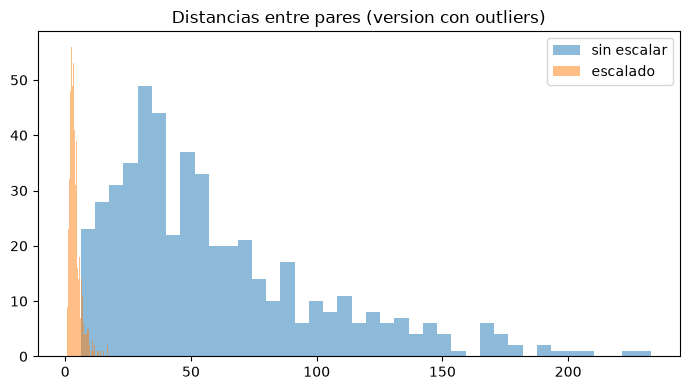

In [11]:
raw_mix = material_difference_summary(df_con, df_sin, "A con outliers", "B sin outliers")
display(raw_mix)

# Parejas de distancia (muestra): sin escalar vs escalado para la version con outliers
numeric_raw = work_con[SELECTED_NUMERIC].reset_index(drop=True)
numeric_scaled = scaled_con.reset_index(drop=True)
distances = pair_distance_analysis(numeric_raw, numeric_scaled, n_rows=400, n_pairs=500, random_state=RANDOM_SEED)
display(distances.describe())
print("Correlacion distancia raw vs scaled:", round(distances.distance_raw.corr(distances.distance_scaled), 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(distances.distance_raw, bins=40, alpha=0.5, label="sin escalar")
ax.hist(distances.distance_scaled, bins=40, alpha=0.5, label="escalado")
ax.set_title("Distancias entre pares (version con outliers)")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Train/test split por persona (`resume_id`)

Regla de oro: split por persona, nunca por fila. Los scalers/encoders/discretizadores se ajustan solo en train y despues transforman test.


In [12]:
# Universo con oficio clasificado y target reincide
train_con, test_con = group_train_test_split(work_con, group_col="resume_id", test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_sin, test_sin = group_train_test_split(work_sin, group_col="resume_id", test_size=TEST_SIZE, random_state=RANDOM_SEED)

print("A con: train/test rows", train_con.shape, test_con.shape)
print("A sin: train/test rows", train_sin.shape, test_sin.shape)
print("Personas con train/test:", train_con.resume_id.nunique(), test_con.resume_id.nunique())


A con: train/test rows (278987, 33) (69276, 33)
A sin: train/test rows (278987, 33) (69276, 33)
Personas con train/test: 56317 14080


In [13]:
DISC_LABELS = DISCRETIZATION_SPEC["labels"]

X_train_con, X_test_con, artifacts_con = fit_transform_train_test(
    train_df=train_con,
    test_df=test_con,
    scaling_plan=scaling_plan,
    onehot_cols=ONEHOT_COLUMNS,
    discretization_spec=DISCRETIZATION_SPEC,
    binary_cols=BINARY_COLUMNS,
    presence_cols=PRESENCE_COLUMNS,
    drop_first=ONEHOT_DROP_FIRST,
)

X_train_sin, X_test_sin, artifacts_sin = fit_transform_train_test(
    train_df=train_sin,
    test_df=test_sin,
    scaling_plan=scaling_plan,
    onehot_cols=ONEHOT_COLUMNS,
    discretization_spec=DISCRETIZATION_SPEC,
    binary_cols=BINARY_COLUMNS,
    presence_cols=PRESENCE_COLUMNS,
    drop_first=ONEHOT_DROP_FIRST,
)

print("X_train_con:", X_train_con.shape, "X_test_con:", X_test_con.shape)
print("X_train_sin:", X_train_sin.shape, "X_test_sin:", X_test_sin.shape)

y_train_con = train_con["reincide"] if TARGET_MODE == "reincide" else None
y_test_con = test_con["reincide"] if TARGET_MODE == "reincide" else None
y_train_sin = train_sin["reincide"] if TARGET_MODE == "reincide" else None
y_test_sin = test_sin["reincide"] if TARGET_MODE == "reincide" else None


X_train_con: (278987, 2839) X_test_con: (69276, 2839)
X_train_sin: (278987, 2839) X_test_sin: (69276, 2839)


## 10. Validacion final

Se comprueban nulos, infinitos, formas, personas compartidas y estadisticos de columnas escaladas. Las dummies deben quedar en 0/1 y Y no debe estar dentro de X.


In [14]:
report_con = validate_transformed(
    X_train=X_train_con,
    X_test=X_test_con,
    y_train=y_train_con,
    y_test=y_test_con,
    train_persons=set(train_con.resume_id.astype(str)),
    test_persons=set(test_con.resume_id.astype(str)),
    scaled_columns=[c for c in scaling_plan if scaled_column_name(c, scaling_plan[c]) in X_train_con.columns],
)
assert_validation(report_con)
print("Reporte A (con):", report_con)

report_sin = validate_transformed(
    X_train=X_train_sin,
    X_test=X_test_sin,
    y_train=y_train_sin,
    y_test=y_test_sin,
    train_persons=set(train_sin.resume_id.astype(str)),
    test_persons=set(test_sin.resume_id.astype(str)),
    scaled_columns=[c for c in scaling_plan if scaled_column_name(c, scaling_plan[c]) in X_train_sin.columns],
)
assert_validation(report_sin)
print("Reporte B (sin):", report_sin)


Reporte A (con): {'X_train_shape': (278987, 2839), 'X_test_shape': (69276, 2839), 'train_nulls': 0, 'test_nulls': 0, 'train_infinities': 0, 'test_infinities': 0, 'shared_persons': 0, 'columns_identical': True, 'binary_like_columns_checked': 2826, 'scaled_columns': {}, 'target_in_features': False, 'y_train_prevalence': 0.30520060074483757, 'y_test_prevalence': 0.30462209134476587}


Reporte B (sin): {'X_train_shape': (278987, 2839), 'X_test_shape': (69276, 2839), 'train_nulls': 0, 'test_nulls': 0, 'train_infinities': 0, 'test_infinities': 0, 'shared_persons': 0, 'columns_identical': True, 'binary_like_columns_checked': 2826, 'scaled_columns': {}, 'target_in_features': False, 'y_train_prevalence': 0.30520060074483757, 'y_test_prevalence': 0.30462209134476587}


## 11. Decision log (CRISP-DM)

La bitacora deja explicita columna, decision, metodo y justificacion para cada transformacion relevante.


In [15]:
log = DecisionLog()
for col in SELECTED_NUMERIC:
    log.add(col, "escalar", SCALING_PLAN.get(col, "robust"), "Numerico con evidencia de skew/outliers segun evidencia de skew/outliers.", "Construct data")
for col in ONEHOT_COLUMNS:
    log.add(col, "one-hot", "OneHotEncoder(drop='first')", "Variable nominal; LabelEncoder quedaria fuera de orden arbitrario.", "Construct data")
log.add("university_level", "ordinal mapping", "map manual 0..4", "Jerarquia genuina de formacion.", "Construct data")
for col in DISCRETIZATION_COLUMNS:
    log.add(col, "discretizar", "KBinsDiscretizer (quantile)", "Segmento interpretable para el negocio; se pierde detalle interno.", "Construct data")
log.add("resume_id", "split", "GroupShuffleSplit", "Evita fuga por persona.", "Format data")
frame_log = log.to_frame()
display(frame_log)
if EXPORT_DECISION_LOG:
    ensure_dir(TRANSFORMED_ROOT / "logs")
    frame_log.to_csv(TRANSFORMED_ROOT / "logs" / "decision_log.csv", index=False, encoding="utf-8")
    print("Decision log exportado.")
else:
    print("Decision log solo en RAM (EXPORT_DECISION_LOG=False).")


,column,decision,method,justification,phase_task
0,start_ord,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
1,end_ord,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
2,dur_q,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
3,n_skills_essential,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
4,n_skills_competence,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
5,n_skills_knowledge,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
6,n_skills_sin_tipo,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
7,veces_ese_oficio,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
8,start_year,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data
9,job_order,escalar,robust,Numerico con evidencia de skew/outliers segun ...,Construct data


Decision log solo en RAM (EXPORT_DECISION_LOG=False).


## 12. Exportacion de X_train, X_test y transformers

Solo se escriben las salidas finales acordadas; los CSV de entrada no se tocan.


In [16]:
# A con outliers
out_con = TRANSFORMED_ROOT / VERSION_CON
for name, frame in [("train/X_train.csv", X_train_con), ("test/X_test.csv", X_test_con)]:
    save_frame(frame, out_con / name)
ensure_dir(out_con / "train")
ensure_dir(out_con / "test")
if y_train_con is not None:
    save_frame(y_train_con.to_frame("reincide"), out_con / "train/y_train.csv")
if y_test_con is not None:
    save_frame(y_test_con.to_frame("reincide"), out_con / "test/y_test.csv")
save_transformers(artifacts_con, TRANSFORMED_ROOT / "transformers" / VERSION_CON)
print("Exportada version con outliers.")

# B sin outliers
out_sin = TRANSFORMED_ROOT / VERSION_SIN
for name, frame in [("train/X_train.csv", X_train_sin), ("test/X_test.csv", X_test_sin)]:
    save_frame(frame, out_sin / name)
ensure_dir(out_sin / "train")
ensure_dir(out_sin / "test")
if y_train_sin is not None:
    save_frame(y_train_sin.to_frame("reincide"), out_sin / "train/y_train.csv")
if y_test_sin is not None:
    save_frame(y_test_sin.to_frame("reincide"), out_sin / "test/y_test.csv")
save_transformers(artifacts_sin, TRANSFORMED_ROOT / "transformers" / VERSION_SIN)
print("Exportada version sin outliers.")
print("Rutas:", TRANSFORMED_ROOT)


Exportada version con outliers.


Exportada version sin outliers.
Rutas: C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed


## 13. CRISP-DM status y siguiente fase

**Logrado:**
- Select data: perfil completo, decision por columna.
- Construct data: fechas, encoding, scaling, discretizacion.
- Integrate data: matrices X finales para A y B.
- Format data: comparacion A/B, diagnostico PCA delegado a 4.x, y train/test por persona.
- Validacion: sin nulos/infinitos, escalado verificado, personas disjuntas, Y fuera de X.

**Riesgos:**
- B winsoriza solo 4 columnas; las demas mantienen su cola real.
- One-hot de occupation_code genera alta dimensionalidad (decision aprobada).
- PCA confirma dependencia lineal entre fechas/duracion, por lo que no comprime valor.
- Split es por persona, pero la repeticion intra-persona aun requiere construccion de S_p en la siguiente fase.

**Siguiente fase (CRISP-DM 4/5):**
- Construir secuencias por persona (S_p) con la X preparada.
- Evaluar estabilidad de patrones/clusters en train vs test.
- Mantener las banderas y metadata fuera de la X para interpretacion.
